# Proyecto 5. Clasificación de flores

**Objetivo:** Adaptar ResNet18 preentrenada mediante transferencia de aprendizaje.

Ejecuten las celdas en orden. Después de **cada celda de código**, respondan las preguntas en la celda de texto siguiente. Guarden evidencia de sus experimentos y justifiquen cada decisión con resultados y fuentes consultadas. Reinicien el entorno y ejecuten todo antes de entregar.

**Entorno:** Google Colab o Python con Jupyter. Instalen una versión compatible de PyTorch y torchvision, además de numpy, matplotlib, pandas, scikit-learn y datasets cuando corresponda. En Colab pueden usar una celda separada con `%pip install torch torchvision numpy matplotlib pandas scikit-learn datasets`; reinicien el entorno si se les solicita. Descargar datos o pesos requiere internet. Oxford Flowers 102 y pesos de ResNet18 se descargan desde torchvision; requiere internet y espacio en disco.

## 1. Importaciones y reproducibilidad

Importamos las herramientas y fijamos una semilla. Los resultados pueden variar según hardware y versiones.

In [4]:
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split
from pathlib import Path


def fijar_semilla(semilla=42):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)


fijar_semilla(42)

# Selección del dispositivo
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Directorios para guardar los resultados
Path("resultados").mkdir(exist_ok=True)
Path("resultados/graficas").mkdir(exist_ok=True)
Path("modelos").mkdir(exist_ok=True)

print("Dispositivo:", device)
print("PyTorch:", torch.__version__)
print("Semilla inicial: 42")

Dispositivo: mps
PyTorch: 2.15.0
Semilla inicial: 42


### Preguntas y actividad obligatoria

1. ¿Qué aporta cada biblioteca? Investiguen la documentación de `torch.device`.
2. Cambien la semilla, ejecuten el proyecto y comparen resultados; ¿garantiza repetir exactamente todos los cálculos?

**Respuestas del equipo:** 

Utilizamos PyTorch para construir y entrenar la red neuronal, NumPy para realizar operaciones numéricas, Matplotlib para visualizar los resultados y torchvision para obtener el dataset y el modelo preentrenado, por nuestro lado nosotros incorporamos pandas para organizar los resultados de los experimentos y time para medir la duración de los entrenamientos.

La función torch.device nos permite indicar en qué dispositivo se realizarán las operaciones del modelo y los tensores, al nosotros usar un equipo MAC adaptamos el código original para que, además de CPU y CUDA, sea compatible con MPS, lo que nos permite aprovechar la GPU de un equipo con Apple Silicon.

Fijamos las semillas aleatorias para mejorar la reproducibilidad de los experimentos. Sin embargo, esto no garantiza resultados exactamente iguales en diferentes dispositivos o versiones de las bibliotecas.

## 2. Datos y conjuntos

Preparen entrenamiento, validación y prueba sin mezclar información entre ellos. La validación sirve para decisiones; la prueba se reserva para la evaluación final.

In [6]:
from torchvision import datasets, transforms, models  # Importa datasets, transformaciones y modelos de visión.
pesos = models.ResNet18_Weights.DEFAULT  # Selecciona los pesos preentrenados oficiales.
transformacion = pesos.transforms()  # Aplica el tamaño y normalización esperados por dichos pesos.
entrenamiento = datasets.Flowers102('datos', split='train', download=True, transform=transformacion)  # Descarga y prepara entrenamiento.
validacion = datasets.Flowers102('datos', split='val', download=True, transform=transformacion)  # Carga validación independiente.
prueba = datasets.Flowers102('datos', split='test', download=True, transform=transformacion)  # Carga prueba independiente.
clases = [f'Flor {i+1}' for i in range(102)]  # Usa identificadores de clase; consulten el catálogo para nombres botánicos.
train_loader = DataLoader(entrenamiento, batch_size=32, shuffle=True)  # Forma lotes mezclados para entrenamiento.
val_loader = DataLoader(validacion, batch_size=32)  # Forma lotes para validación.
test_loader = DataLoader(prueba, batch_size=32)  # Forma lotes para prueba.
print('Clases:', clases, '| tamaños:', len(entrenamiento), len(validacion), len(prueba))  # Muestra las clases y particiones.


100.0%
100.0%


Clases: ['Flor 1', 'Flor 2', 'Flor 3', 'Flor 4', 'Flor 5', 'Flor 6', 'Flor 7', 'Flor 8', 'Flor 9', 'Flor 10', 'Flor 11', 'Flor 12', 'Flor 13', 'Flor 14', 'Flor 15', 'Flor 16', 'Flor 17', 'Flor 18', 'Flor 19', 'Flor 20', 'Flor 21', 'Flor 22', 'Flor 23', 'Flor 24', 'Flor 25', 'Flor 26', 'Flor 27', 'Flor 28', 'Flor 29', 'Flor 30', 'Flor 31', 'Flor 32', 'Flor 33', 'Flor 34', 'Flor 35', 'Flor 36', 'Flor 37', 'Flor 38', 'Flor 39', 'Flor 40', 'Flor 41', 'Flor 42', 'Flor 43', 'Flor 44', 'Flor 45', 'Flor 46', 'Flor 47', 'Flor 48', 'Flor 49', 'Flor 50', 'Flor 51', 'Flor 52', 'Flor 53', 'Flor 54', 'Flor 55', 'Flor 56', 'Flor 57', 'Flor 58', 'Flor 59', 'Flor 60', 'Flor 61', 'Flor 62', 'Flor 63', 'Flor 64', 'Flor 65', 'Flor 66', 'Flor 67', 'Flor 68', 'Flor 69', 'Flor 70', 'Flor 71', 'Flor 72', 'Flor 73', 'Flor 74', 'Flor 75', 'Flor 76', 'Flor 77', 'Flor 78', 'Flor 79', 'Flor 80', 'Flor 81', 'Flor 82', 'Flor 83', 'Flor 84', 'Flor 85', 'Flor 86', 'Flor 87', 'Flor 88', 'Flor 89', 'Flor 90', 'Flor 91',

In [7]:
fijar_semilla(42)

imagenes, etiquetas = next(iter(train_loader))

print("Dimensiones de las imágenes:", imagenes.shape)
print("Dimensiones de las etiquetas:", etiquetas.shape)
print("Tipo de imágenes:", imagenes.dtype)
print("Tipo de etiquetas:", etiquetas.dtype)
print("Lotes de entrenamiento:", len(train_loader))
print("Lotes de validación:", len(val_loader))

Dimensiones de las imágenes: torch.Size([32, 3, 224, 224])
Dimensiones de las etiquetas: torch.Size([32])
Tipo de imágenes: torch.float32
Tipo de etiquetas: torch.int64
Lotes de entrenamiento: 32
Lotes de validación: 32


### Preguntas y actividad obligatoria

1. ¿Qué representa cada conjunto y cuántos ejemplos contiene?
2. Investiguen por qué no debe ajustarse el modelo con prueba. Cambien el tamaño del lote, vuelvan a ejecutar y comparen tiempo y resultados.

**Respuestas del equipo:** 

El dataset Oxford Flowers 102 contiene 8,189 imágenes correspondientes a 102 clases de flores, las cuales se encuentran divididas en tres conjuntos:

Entrenamiento: 1,020 imágenes utilizadas para ajustar los parámetros del modelo.

Validación: 1,020 imágenes utilizadas para evaluar el aprendizaje y comparar las diferentes configuraciones.

Prueba: 6,149 imágenes reservadas para evaluar el desempeño final del modelo.

Tanto entrenamiento como validación contienen 10 imágenes por cada clase, mientras que el conjunto de prueba presenta una distribución desigual.

No debemos utilizar el conjunto de prueba para ajustar el modelo o seleccionar hiperparámetros, ya que perderíamos la posibilidad de realizar una evaluación independiente y podríamos obtener resultados demasiado optimistas.

En el experimento EXP-05 aumentamos el tamaño del lote de 32 a 64 imágenes. Esto redujo de 32 a 16 la cantidad de actualizaciones de los parámetros por época, manteniendo la misma cantidad de imágenes procesadas.

## 3. Arquitectura y entrenamiento

El modelo recibe imágenes preparadas con la transformación asociada a sus pesos.

In [8]:
def crear_modelo(fine_tuning=False):

    # Cargar ResNet18 con pesos preentrenados
    modelo = models.resnet18(weights=pesos)

    # Congelar los parámetros originales
    for parametro in modelo.parameters():
        parametro.requires_grad = False

    # Reemplazar la capa clasificadora
    modelo.fc = nn.Linear(
        modelo.fc.in_features,
        len(clases)
    )

    # Descongelar el último bloque si se solicita
    if fine_tuning:
        for parametro in modelo.layer4.parameters():
            parametro.requires_grad = True

    return modelo.to(device)

In [9]:
fijar_semilla(42)

modelo = crear_modelo()

total_parametros = sum(
    p.numel() for p in modelo.parameters()
)

parametros_entrenables = sum(
    p.numel() for p in modelo.parameters()
    if p.requires_grad
)

print("Parámetros totales:", total_parametros)
print("Parámetros entrenables:", parametros_entrenables)
print("Dispositivo:", next(modelo.parameters()).device)
print("Capa final:", modelo.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/emv03/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


Parámetros totales: 11228838
Parámetros entrenables: 52326
Dispositivo: mps:0
Capa final: Linear(in_features=512, out_features=102, bias=True)


In [10]:
def evaluar(modelo, loader, criterio):

    modelo.eval()

    perdida_total = 0.0
    aciertos = 0
    total = 0

    with torch.no_grad():

        for imagenes, etiquetas in loader:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = modelo(imagenes)
            perdida = criterio(salidas, etiquetas)

            predicciones = salidas.argmax(dim=1)

            perdida_total += perdida.item() * etiquetas.size(0)

            aciertos += (
                predicciones == etiquetas
            ).sum().item()

            total += etiquetas.size(0)

    return perdida_total / total, aciertos / total

In [11]:
criterio = nn.CrossEntropyLoss()

perdida_inicial, accuracy_inicial = evaluar(
    modelo,
    val_loader,
    criterio
)

print(f"Pérdida inicial: {perdida_inicial:.4f}")
print(f"Accuracy inicial: {accuracy_inicial:.2%}")

Pérdida inicial: 4.8163
Accuracy inicial: 1.37%


In [12]:
def modo_entrenamiento(modelo, fine_tuning=False):

    # Mantener congeladas las estadísticas
    # de las capas que no estamos entrenando
    modelo.eval()

    # Activar el entrenamiento del clasificador
    modelo.fc.train()

    # Activar el último bloque si corresponde
    if fine_tuning:
        modelo.layer4.train()

### Preguntas y actividad obligatoria

1. Dibujen la arquitectura e indiquen la forma de entrada y salida de cada componente.
2. Investiguen y justifiquen la pérdida, activación, optimizador y tasa de aprendizaje.
3. Modifiquen un hiperparámetro, reentrenen y comparen con el resultado original.

**Respuestas del equipo:**

Utilizamos ResNet18 preentrenada con ImageNet, reemplazando su capa clasificadora original por una capa lineal de 102 salidas, una por cada clase de flor.

La entrada tiene dimensiones (B, 3, 224, 224), donde B representa el tamaño del lote. Después de pasar por las capas convolucionales y las operaciones de pooling, se obtiene un vector de 512 características por imagen. Finalmente, la capa clasificadora transforma estas características en 102 puntuaciones.

Utilizamos CrossEntropyLoss como función de pérdida debido a que nuestro problema es de clasificación multiclase y cada imagen pertenece únicamente a una clase.

ResNet18 utiliza principalmente ReLU como función de activación en sus bloques internos, lo que permite introducir relaciones no lineales y aprender características más complejas de las imágenes.

En la última capa no aplicamos Softmax directamente, ya que CrossEntropyLoss realiza internamente las operaciones necesarias para trabajar con las puntuaciones de salida del modelo.

Elegimos Adam como optimizador porque ajusta de manera adaptativa las actualizaciones de los parámetros utilizando información de los gradientes.

Inicialmente utilizamos una tasa de aprendizaje de 0.001, la cual determina la escala de las actualizaciones de los parámetros durante el entrenamiento.

En EXP-02 redujimos la tasa de aprendizaje de 0.001 a 0.0005, conservando los demás hiperparámetros.

La configuración base obtuvo una exactitud de validación de 75.69 %, mientras que EXP-02 obtuvo 68.53 %. Esto representa una disminución de 7.16 puntos porcentuales.

Observamos que una tasa de aprendizaje menor produjo un aprendizaje más lento durante las cinco épocas realizadas. Esto no significa que una tasa de aprendizaje menor sea siempre perjudicial, ya que podría requerir un mayor número de épocas para alcanzar mejores resultados.

## 4. Ciclo de entrenamiento

En entrenamiento se calculan gradientes y se actualizan parámetros. En validación se desactiva el cálculo de gradientes.

In [13]:
def entrenar_experimento(
    nombre,
    epocas=5,
    lr=0.001,
    batch_size=32,
    semilla=42,
    fine_tuning=False
):

    # Reproducibilidad
    fijar_semilla(semilla)

    # Inicializar un modelo independiente
    modelo = crear_modelo(fine_tuning)

    # Crear los DataLoaders
    generador = torch.Generator()
    generador.manual_seed(semilla)

    loader_train = DataLoader(
        entrenamiento,
        batch_size=batch_size,
        shuffle=True,
        generator=generador
    )

    loader_val = DataLoader(
        validacion,
        batch_size=batch_size,
        shuffle=False
    )

    # Función de pérdida
    criterio = nn.CrossEntropyLoss()

    # Optimizador
    optimizador = torch.optim.Adam(
        filter(
            lambda p: p.requires_grad,
            modelo.parameters()
        ),
        lr=lr
    )

    historial = []

    mejor_accuracy = -1.0
    mejor_perdida = float("inf")
    mejores_pesos = None
    mejor_epoca = 0

    # Sincronizar GPU antes de medir
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    print(f"\nIniciando experimento: {nombre}")
    print(f"Dispositivo: {device}")

    for epoca in range(epocas):

        modo_entrenamiento(modelo, fine_tuning)

        perdida_total = 0.0
        aciertos = 0
        total = 0

        for imagenes, etiquetas in loader_train:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            # Limpiar gradientes
            optimizador.zero_grad()

            # Forward propagation
            salidas = modelo(imagenes)

            # Calcular la pérdida
            perdida = criterio(salidas, etiquetas)

            # Backpropagation
            perdida.backward()

            # Actualizar parámetros
            optimizador.step()

            # Métricas de entrenamiento
            predicciones = salidas.argmax(dim=1)

            perdida_total += (
                perdida.item() * etiquetas.size(0)
            )

            aciertos += (
                predicciones == etiquetas
            ).sum().item()

            total += etiquetas.size(0)

        train_loss = perdida_total / total
        train_acc = aciertos / total

        # Evaluación en validación
        val_loss, val_acc = evaluar(
            modelo,
            loader_val,
            criterio
        )

        # Registrar métricas
        historial.append({
            "experimento": nombre,
            "epoca": epoca + 1,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        })

        # Conservar el mejor modelo
        if (
            val_acc > mejor_accuracy
            or (
                val_acc == mejor_accuracy
                and val_loss < mejor_perdida
            )
        ):
            mejor_accuracy = val_acc
            mejor_perdida = val_loss
            mejor_epoca = epoca + 1

            mejores_pesos = {
                k: v.detach().cpu().clone()
                for k, v in modelo.state_dict().items()
            }

        print(
            f"Época {epoca + 1}/{epocas} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train acc: {train_acc:.2%} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val acc: {val_acc:.2%}"
        )

    # Sincronizar GPU antes de detener el reloj
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    tiempo_total = time.perf_counter() - inicio

    # Restaurar los mejores pesos
    modelo.load_state_dict(mejores_pesos)
    modelo.eval()

    # Resumen del experimento
    resultado = {
        "experimento": nombre,
        "semilla": semilla,
        "epocas": epocas,
        "learning_rate": lr,
        "batch_size": batch_size,
        "fine_tuning": fine_tuning,
        "optimizador": "Adam",
        "dispositivo": str(device),
        "parametros_entrenables": sum(
            p.numel() for p in modelo.parameters()
            if p.requires_grad
        ),
        "mejor_epoca": mejor_epoca,
        "mejor_val_acc": mejor_accuracy,
        "mejor_val_loss": mejor_perdida,
        "tiempo_segundos": tiempo_total
    }

    # Exportar el historial
    pd.DataFrame(historial).to_csv(
        f"resultados/{nombre}_historial.csv",
        index=False
    )

    # Exportar el resumen
    pd.DataFrame([resultado]).to_csv(
        f"resultados/{nombre}_resumen.csv",
        index=False
    )

    # Guardar pesos y metadatos
    torch.save({
        "model_state_dict": mejores_pesos,
        "configuracion": resultado,
        "arquitectura": "resnet18",
        "num_clases": len(clases),
        "clases": clases
    }, f"modelos/{nombre}.pth")

    print(f"\nExperimento {nombre} finalizado")
    print(f"Mejor época: {mejor_epoca}")
    print(f"Mejor accuracy: {mejor_accuracy:.2%}")
    print(f"Tiempo: {tiempo_total / 60:.2f} minutos")

    return modelo, historial, resultado

In [14]:
modelo_base, historial_base, resultado_base = (
    entrenar_experimento(
        nombre="BASE",
        epocas=5,
        lr=0.001,
        batch_size=32,
        semilla=42,
        fine_tuning=False
    )
)


Iniciando experimento: BASE
Dispositivo: mps
Época 1/5 | Train loss: 4.5653 | Train acc: 5.88% | Val loss: 3.8607 | Val acc: 22.45%
Época 2/5 | Train loss: 3.2869 | Train acc: 42.06% | Val loss: 2.9892 | Val acc: 53.24%
Época 3/5 | Train loss: 2.3864 | Train acc: 71.18% | Val loss: 2.4240 | Val acc: 64.22%
Época 4/5 | Train loss: 1.7973 | Train acc: 83.82% | Val loss: 2.0154 | Val acc: 73.33%
Época 5/5 | Train loss: 1.3747 | Train acc: 89.71% | Val loss: 1.7359 | Val acc: 75.69%

Experimento BASE finalizado
Mejor época: 5
Mejor accuracy: 75.69%
Tiempo: 1.03 minutos


In [15]:
modelo_exp01, historial_exp01, resultado_exp01 = (
    entrenar_experimento(
        nombre="EXP-01",
        epocas=10,
        lr=0.001,
        batch_size=32,
        semilla=42,
        fine_tuning=False
    )
)


Iniciando experimento: EXP-01
Dispositivo: mps
Época 1/10 | Train loss: 4.5653 | Train acc: 5.88% | Val loss: 3.8607 | Val acc: 22.45%
Época 2/10 | Train loss: 3.2869 | Train acc: 42.06% | Val loss: 2.9892 | Val acc: 53.24%
Época 3/10 | Train loss: 2.3864 | Train acc: 71.18% | Val loss: 2.4240 | Val acc: 64.22%
Época 4/10 | Train loss: 1.7973 | Train acc: 83.82% | Val loss: 2.0154 | Val acc: 73.33%
Época 5/10 | Train loss: 1.3747 | Train acc: 89.71% | Val loss: 1.7359 | Val acc: 75.69%
Época 6/10 | Train loss: 1.0825 | Train acc: 92.16% | Val loss: 1.5301 | Val acc: 78.63%
Época 7/10 | Train loss: 0.8691 | Train acc: 94.61% | Val loss: 1.3834 | Val acc: 81.67%
Época 8/10 | Train loss: 0.7162 | Train acc: 96.18% | Val loss: 1.2642 | Val acc: 82.06%
Época 9/10 | Train loss: 0.6032 | Train acc: 97.35% | Val loss: 1.1833 | Val acc: 81.57%
Época 10/10 | Train loss: 0.5107 | Train acc: 97.65% | Val loss: 1.1091 | Val acc: 83.43%

Experimento EXP-01 finalizado
Mejor época: 10
Mejor accuracy:

In [16]:
modelo_exp02, historial_exp02, resultado_exp02 = (
    entrenar_experimento(
        nombre="EXP-02",
        epocas=5,
        lr=0.0005,
        batch_size=32,
        semilla=42,
        fine_tuning=False
    )
)


Iniciando experimento: EXP-02
Dispositivo: mps
Época 1/5 | Train loss: 4.6554 | Train acc: 2.94% | Val loss: 4.1961 | Val acc: 12.55%
Época 2/5 | Train loss: 3.8973 | Train acc: 23.24% | Val loss: 3.6842 | Val acc: 37.75%
Época 3/5 | Train loss: 3.3097 | Train acc: 53.92% | Val loss: 3.2431 | Val acc: 54.12%
Época 4/5 | Train loss: 2.8154 | Train acc: 71.96% | Val loss: 2.8735 | Val acc: 64.51%
Época 5/5 | Train loss: 2.3966 | Train acc: 80.20% | Val loss: 2.5648 | Val acc: 68.53%

Experimento EXP-02 finalizado
Mejor época: 5
Mejor accuracy: 68.53%
Tiempo: 1.02 minutos


In [17]:
modelo_exp03, historial_exp03, resultado_exp03 = (
    entrenar_experimento(
        nombre="EXP-03",
        epocas=5,
        lr=0.001,
        batch_size=32,
        semilla=42,
        fine_tuning=True
    )
)


Iniciando experimento: EXP-03
Dispositivo: mps
Época 1/5 | Train loss: 3.0526 | Train acc: 38.24% | Val loss: 1.3517 | Val acc: 64.90%
Época 2/5 | Train loss: 0.5500 | Train acc: 92.65% | Val loss: 0.7866 | Val acc: 85.10%
Época 3/5 | Train loss: 0.0872 | Train acc: 99.71% | Val loss: 0.6039 | Val acc: 87.65%
Época 4/5 | Train loss: 0.0241 | Train acc: 100.00% | Val loss: 0.4966 | Val acc: 91.18%
Época 5/5 | Train loss: 0.0100 | Train acc: 100.00% | Val loss: 0.4620 | Val acc: 92.16%

Experimento EXP-03 finalizado
Mejor época: 5
Mejor accuracy: 92.16%
Tiempo: 1.09 minutos


In [26]:
modelo_exp04, historial_exp04, resultado_exp04 = (
    entrenar_experimento(
        nombre="EXP-04",
        epocas=5,
        lr=0.001,
        batch_size=32,
        semilla=7,
        fine_tuning=False
    )
)


Iniciando experimento: EXP-04
Dispositivo: mps
Época 1/5 | Train loss: 4.4827 | Train acc: 7.75% | Val loss: 3.7786 | Val acc: 24.02%
Época 2/5 | Train loss: 3.2136 | Train acc: 44.12% | Val loss: 2.9294 | Val acc: 50.59%
Época 3/5 | Train loss: 2.3414 | Train acc: 73.73% | Val loss: 2.3485 | Val acc: 68.04%
Época 4/5 | Train loss: 1.7348 | Train acc: 86.86% | Val loss: 1.9588 | Val acc: 74.71%
Época 5/5 | Train loss: 1.3276 | Train acc: 91.18% | Val loss: 1.7016 | Val acc: 76.37%

Experimento EXP-04 finalizado
Mejor época: 5
Mejor accuracy: 76.37%
Tiempo: 0.93 minutos


In [27]:
modelo_exp05, historial_exp05, resultado_exp05 = (
    entrenar_experimento(
        nombre="EXP-05",
        epocas=5,
        lr=0.001,
        batch_size=64,
        semilla=42,
        fine_tuning=False
    )
)


Iniciando experimento: EXP-05
Dispositivo: mps
Época 1/5 | Train loss: 4.6354 | Train acc: 4.02% | Val loss: 4.0957 | Val acc: 15.49%
Época 2/5 | Train loss: 3.7206 | Train acc: 29.41% | Val loss: 3.4606 | Val acc: 44.71%
Época 3/5 | Train loss: 3.0056 | Train acc: 58.43% | Val loss: 2.9436 | Val acc: 60.39%
Época 4/5 | Train loss: 2.4211 | Train acc: 79.02% | Val loss: 2.5361 | Val acc: 68.92%
Época 5/5 | Train loss: 1.9799 | Train acc: 84.61% | Val loss: 2.2156 | Val acc: 73.43%

Experimento EXP-05 finalizado
Mejor época: 5
Mejor accuracy: 73.43%
Tiempo: 0.98 minutos


In [28]:
resultados = pd.DataFrame([
    resultado_base,
    resultado_exp01,
    resultado_exp02,
    resultado_exp03,
    resultado_exp04,
    resultado_exp05
])

resultados = resultados.sort_values(
    by=["mejor_val_acc", "mejor_val_loss"],
    ascending=[False, True]
).reset_index(drop=True)

resultados.to_csv(
    "resultados/comparacion_experimentos.csv",
    index=False
)

display(resultados)

,experimento,semilla,epocas,learning_rate,batch_size,fine_tuning,optimizador,dispositivo,parametros_entrenables,mejor_epoca,mejor_val_acc,mejor_val_loss,tiempo_segundos
0,EXP-03,42,5,0.0010,32,True,Adam,mps,8446054,5,0.921569,0.461961,65.485279
1,EXP-01,42,10,0.0010,32,False,Adam,mps,52326,10,0.834314,1.109051,114.463781
2,EXP-04,7,5,0.0010,32,False,Adam,mps,52326,5,0.763725,1.701634,56.070495
3,BASE,42,5,0.0010,32,False,Adam,mps,52326,5,0.756863,1.735899,61.761942
4,EXP-05,42,5,0.0010,64,False,Adam,mps,52326,5,0.734314,2.215634,58.972292
5,EXP-02,42,5,0.0005,32,False,Adam,mps,52326,5,0.685294,2.564801,60.941401


In [29]:
historial_completo = pd.concat([
    pd.DataFrame(historial_base),
    pd.DataFrame(historial_exp01),
    pd.DataFrame(historial_exp02),
    pd.DataFrame(historial_exp03),
    pd.DataFrame(historial_exp04),
    pd.DataFrame(historial_exp05)
], ignore_index=True)

historial_completo.to_csv(
    "resultados/historial_completo.csv",
    index=False
)

display(historial_completo)

,experimento,epoca,train_loss,train_acc,val_loss,val_acc
0,BASE,1,4.565324,0.058824,3.860703,0.224510
1,BASE,2,3.286891,0.420588,2.989201,0.532353
2,BASE,3,2.386419,0.711765,2.423991,0.642157
3,BASE,4,1.797319,0.838235,2.015362,0.733333
4,BASE,5,1.374692,0.897059,1.735899,0.756863
5,EXP-01,1,4.565324,0.058824,3.860703,0.224510
6,EXP-01,2,3.286891,0.420588,2.989201,0.532353
7,EXP-01,3,2.386419,0.711765,2.423991,0.642157
8,EXP-01,4,1.797319,0.838235,2.015362,0.733333
9,EXP-01,5,1.374692,0.897059,1.735899,0.756863


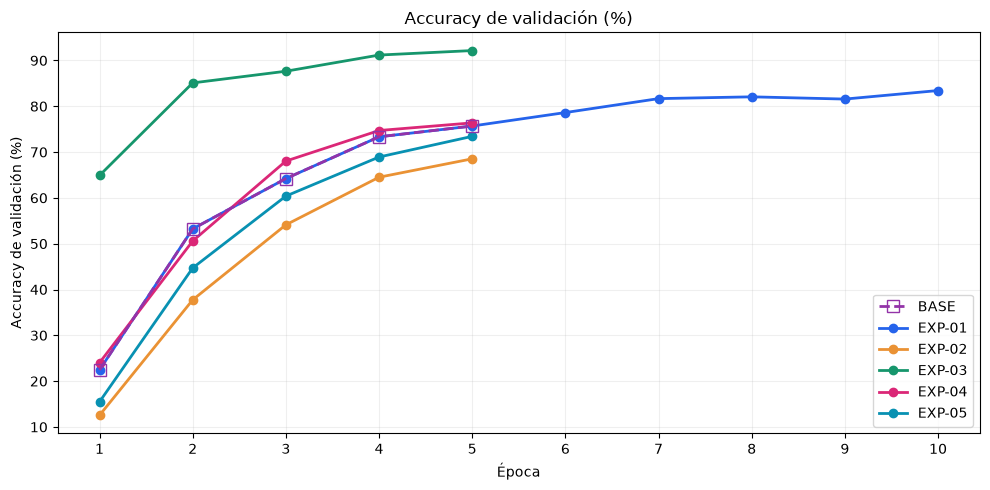

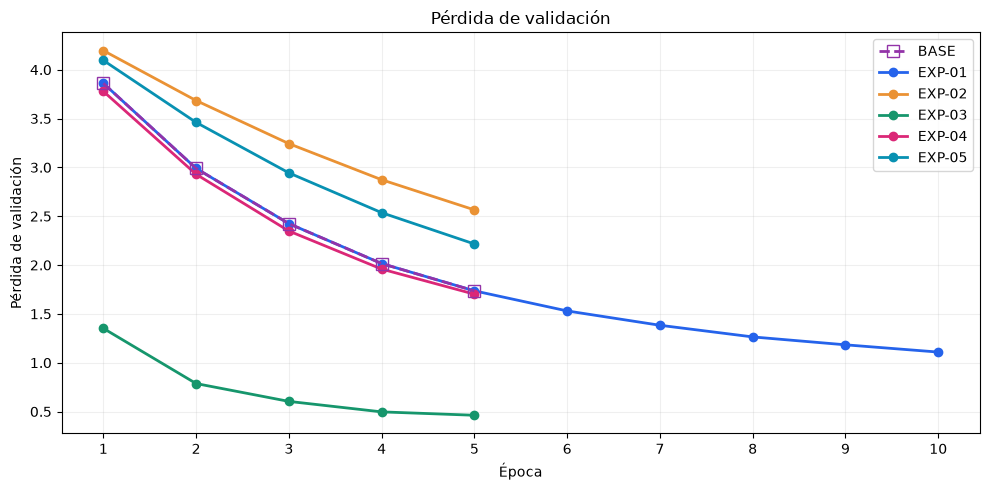

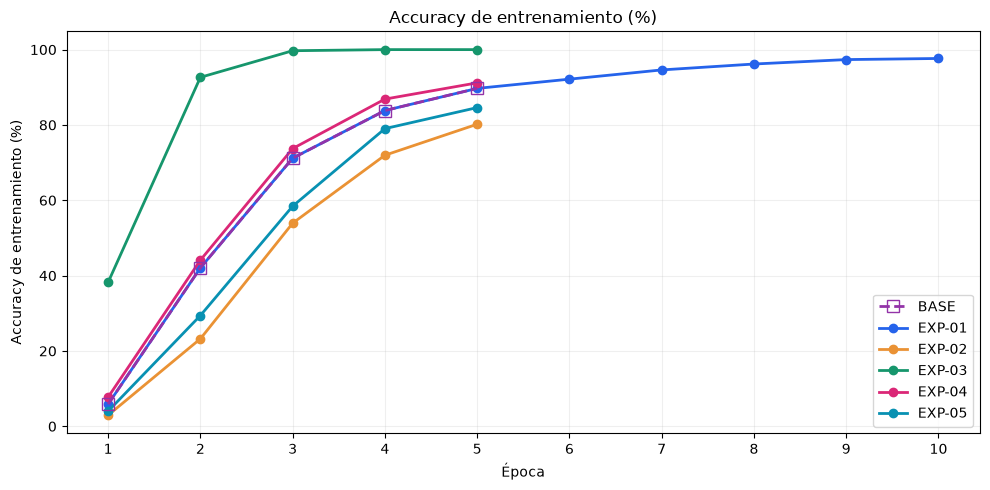

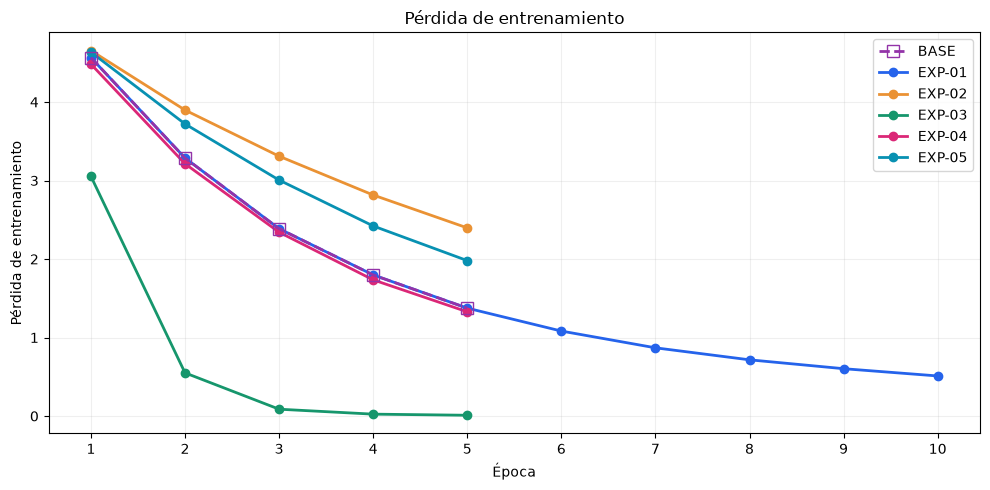

In [30]:
colores = {
    "BASE": "#9333a8",
    "EXP-01": "#2563eb",
    "EXP-02": "#ea9234",
    "EXP-03": "#16966c",
    "EXP-04": "#db2777",
    "EXP-05": "#0891b2"
}

metricas = {
    "val_acc": "Accuracy de validación (%)",
    "val_loss": "Pérdida de validación",
    "train_acc": "Accuracy de entrenamiento (%)",
    "train_loss": "Pérdida de entrenamiento"
}

for metrica, titulo in metricas.items():

    plt.figure(figsize=(10, 5))

    for nombre, grupo in historial_completo.groupby(
        "experimento"
    ):
        valores = grupo[metrica]

        if metrica.endswith("acc"):
            valores = valores * 100

        es_base = nombre == "BASE"

        plt.plot(
            grupo["epoca"],
            valores,
            label=nombre,
            color=colores[nombre],
            linestyle="--" if es_base else "-",
            marker="s" if es_base else "o",
            markersize=9 if es_base else 6,
            markerfacecolor="none" if es_base else colores[nombre],
            linewidth=2,
            zorder=10 if es_base else 2
        )

    plt.title(titulo)
    plt.xlabel("Época")
    plt.ylabel(titulo)
    plt.xticks(range(1, 11))
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"resultados/graficas/{metrica}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

In [22]:
import shutil

ganador = resultados.iloc[0]

nombre_ganador = ganador["experimento"]

shutil.copy2(
    f"modelos/{nombre_ganador}.pth",
    "modelos/modelo_final.pth"
)

print("Modelo seleccionado:", nombre_ganador)

print(
    f"Accuracy de validación: "
    f"{ganador['mejor_val_acc']:.2%}"
)

print("Modelo guardado: modelos/modelo_final.pth")

Modelo seleccionado: EXP-03
Accuracy de validación: 92.16%
Modelo guardado: modelos/modelo_final.pth


In [24]:
checkpoint = torch.load(
    "modelos/modelo_final.pth",
    map_location="cpu",
    weights_only=True
)

modelo_final = crear_modelo(
    fine_tuning=checkpoint["configuracion"]["fine_tuning"]
)

modelo_final.load_state_dict(
    checkpoint["model_state_dict"]
)

modelo_final.eval()

perdida_final, accuracy_final = evaluar(
    modelo_final,
    val_loader,
    nn.CrossEntropyLoss()
)

print("Modelo recuperado correctamente")
print("Arquitectura:", checkpoint["arquitectura"])
print("Número de clases:", checkpoint["num_clases"])
print(f"Validation loss: {perdida_final:.4f}")
print(f"Validation accuracy: {accuracy_final:.2%}")

Modelo recuperado correctamente
Arquitectura: resnet18
Número de clases: 102
Validation loss: 0.4620
Validation accuracy: 92.16%


### Preguntas y actividad obligatoria

1. Expliquen `zero_grad`, `backward` y `step` y qué ocurre si cambia su orden.
2. ¿Qué diferencias hay entre `train`, `eval` y `no_grad`? Investiguen.
3. Dupliquen las épocas y comparen entrenamiento y validación; ¿observan sobreajuste?

**Respuestas del equipo:** escriban aquí sus respuestas y evidencias.

## 5. Curvas y prueba

Utilicen la prueba solo después de tomar sus decisiones con validación.

In [25]:
# Evaluación del modelo seleccionado en el conjunto de prueba.
# Esta celda deberá ser ejecutada por la Persona 4.

test_loss, test_acc = evaluar(
    modelo_final,
    test_loader,
    nn.CrossEntropyLoss()
)

print(f"Pérdida en prueba: {test_loss:.4f}")
print(f"Accuracy en prueba: {test_acc:.2%}")


KeyboardInterrupt: 

### Preguntas y actividad obligatoria

1. ¿Qué tendencia tienen las curvas? ¿Hay evidencia de sobreajuste?
2. ¿Qué significa la exactitud y qué información no proporciona? Investíguenlo.
3. Registren los resultados de sus experimentos y justifiquen su configuración final.

**Respuestas del equipo:** escriban aquí sus respuestas y evidencias.

## 6. Errores y matriz de confusión

Las filas indican la clase real y las columnas la predicción.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report  # Importa herramientas de evaluación.
reales, predichos = [], []  # Prepara listas para etiquetas y predicciones.
modelo.eval()  # Activa el modo de evaluación.
with torch.no_grad():  # Desactiva el cálculo de gradientes.
    for x, y in test_loader:  # Recorre el conjunto de prueba.
        pred = modelo(x.to(device)).argmax(1).cpu()  # Obtiene la clase más probable.
        reales.extend(y.tolist())  # Guarda las etiquetas verdaderas.
        predichos.extend(pred.tolist())  # Guarda las clases predichas.
matriz = confusion_matrix(reales, predichos, labels=list(range(len(clases))))  # Cuenta aciertos y confusiones.
ConfusionMatrixDisplay(matriz, display_labels=clases).plot(xticks_rotation=90, cmap='Blues')  # Grafica la matriz.
plt.show()  # Muestra la matriz.
print(classification_report(reales, predichos, labels=list(range(len(clases))), target_names=clases, zero_division=0))  # Muestra métricas por clase.


### Preguntas y actividad obligatoria

1. Identifiquen dos confusiones frecuentes y propongan una explicación.
2. Investiguen precisión, recall y F1; ¿qué aporta cada una?
3. Seleccionen al menos tres errores y expliquen por qué podrían ser difíciles.

**Respuestas del equipo:** escriban aquí sus respuestas y evidencias.

## 7. Guardado, carga e inferencia

El archivo contiene pesos y metadatos para reproducir la configuración. Conserven también el código y el preprocesamiento.

In [ ]:
ruta_modelo = Path('modelo_entrenado.pth')  # Define el nombre del archivo de salida.
torch.save({'pesos': modelo.state_dict(), 'clases': clases}, ruta_modelo)  # Guarda pesos y nombres de clases.
checkpoint = torch.load(ruta_modelo, map_location=device, weights_only=True)  # Carga el archivo confiable en el dispositivo elegido.
modelo.load_state_dict(checkpoint['pesos'])  # Restaura los parámetros en la arquitectura definida.
modelo.eval()  # Prepara la red para inferencia.
x, y = next(iter(test_loader))  # Obtiene un lote que no se usó para entrenar.
with torch.no_grad():  # Desactiva gradientes durante la predicción.
    probabilidades = torch.softmax(modelo(x[:1].to(device)), dim=1)[0].cpu()  # Convierte puntuaciones en probabilidades normalizadas.
indice = probabilidades.argmax().item()  # Localiza la clase con mayor puntuación.
print('Real:', clases[y[0].item()], '| Predicción:', clases[indice], '| Confianza:', round(probabilidades[indice].item(), 3))  # Presenta el resultado.


### Preguntas y actividad obligatoria

1. ¿Por qué deben conservar arquitectura y preprocesamiento además de pesos?
2. ¿Qué representa softmax y por qué una confianza alta puede ser incorrecta?
3. Prueben al menos cinco ejemplos, registren resultados y expliquen errores. Investiguen cómo descongelar layer4 y reconstruir el optimizador; comparen con la capa congelada.

**Respuestas del equipo:** escriban aquí sus respuestas y evidencias.

## Entrega y defensa

Entreguen el notebook ejecutado, modelo, fuentes y reporte. Incluyan una tabla con configuración inicial, modificaciones, métricas y explicación. Respondan todas las preguntas, citen la documentación consultada y expliquen qué cambiarían. No seleccionen hiperparámetros usando prueba.

## 8. Tres clases más probables

Top-3 muestra alternativas; no garantiza que las probabilidades estén calibradas.

In [ ]:
x, y = next(iter(test_loader))  # Obtiene un lote de prueba.
with torch.no_grad():  # Evita gradientes durante inferencia.
    p = torch.softmax(modelo(x[:1].to(device)), dim=1)[0].cpu()  # Calcula puntuaciones normalizadas.
valores, indices = p.topk(3)  # Selecciona las tres puntuaciones mayores.
for valor, indice in zip(valores, indices):  # Recorre puntuaciones y clases seleccionadas.
    print(clases[indice.item()], round(valor.item(), 3))  # Muestra cada clase y su confianza.
print('Clase real:', clases[y[0].item()])  # Muestra la etiqueta verdadera.


### Preguntas y actividad obligatoria

1. ¿La clase real aparece entre las tres primeras?
2. Investiguen Top-1 y Top-3 y calculen Top-3 para toda la prueba. Justifiquen su interpretación.

**Respuestas del equipo:** escriban aquí sus respuestas y evidencias.

# Referencias

Reproducibilidad	    [PyTorch Reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html?utm_source=chatgpt.com)

Aceleración en Mac	     [MPS Backend](https://docs.pytorch.org/docs/stable/notes/mps.html?utm_source=chatgpt.com)

Función de pérdida	     [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html?utm_source=chatgpt.com)

Optimizador	             [Adam](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html?utm_source=chatgpt.com)

Gradientes	             [Autograd](https://docs.pytorch.org/docs/stable/notes/autograd.html?utm_source=chatgpt.com)

Transferencia de aprendizaje    [Transfer Learning Tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html?utm_source=chatgpt.com)